# PRCP-1003 — Customer Transaction Prediction
**Domain:** Banking  
**Objective:** Analyze the supplied data and predict whether a customer will make a future transaction, regardless of transaction amount.

## 1. Business understanding

The target column is binary:
- `0`: customer will not make a transaction.
- `1`: customer will make a transaction.

The dataset is anonymized and contains `ID_code`, 200 unnamed/anonymized feature columns, and `target`. Since the feature meanings are not available, feature-level business interpretation is limited. The model should be evaluated using class-sensitive metrics as well as ranking metrics; accuracy alone can be misleading if the target classes are imbalanced.

In [1]:
# 2. Import required libraries
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Libraries imported successfully.
NumPy: 2.4.6
Pandas: 3.0.3


## 3. Load the Data Set :

In [2]:
# Update only if your training CSV has a different name/location.
DATA_DIR = Path(r"D:\Datamites\Projects\Capstone_Project 4")
TRAIN_FILE = None  # Example: DATA_DIR / "train.csv"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Check the folder path or update DATA_DIR."
    )

if TRAIN_FILE is not None:
    train_path = Path(TRAIN_FILE)
else:
    csv_files = sorted(DATA_DIR.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError(f"No CSV files found inside {DATA_DIR}")

    train_candidates = [p for p in csv_files if p.name.lower() == "train.csv"]
    if train_candidates:
        train_path = train_candidates[0]
    else:
        # Inspect headers to find a file containing the target column.
        train_path = None
        for candidate in csv_files:
            try:
                if "target" in pd.read_csv(candidate, nrows=5).columns:
                    train_path = candidate
                    break
            except Exception:
                pass
        if train_path is None:
            raise FileNotFoundError(
                "Could not identify a training CSV containing a 'target' column. "
                "Set TRAIN_FILE manually."
            )

print("Selected training file:", train_path)
df = pd.read_csv(train_path)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Selected training file: D:\Datamites\Projects\Capstone_Project 4\PRCP-1003-CustTransPred\Data\train(1).csv
Dataset loaded successfully.
Shape: (200000, 202)


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


## 4. Data quality and dataset summary

The project brief says detailed EDA may be skipped because the feature names are anonymized. The following checks are retained because they are necessary for reliable modelling: dimensions, column names, data types, missing values, duplicate rows, target validity, and class balance.

Rows: 200000
Columns: 202

Column data types:


,Column count
Data type,
float64,200
str,1
int64,1



Missing values (top 15):


,Missing count
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0
var_7,0



Duplicate rows: 0

Target values: [0, 1]


,Count,Percentage
target,,
0,179902,89.95
1,20098,10.05


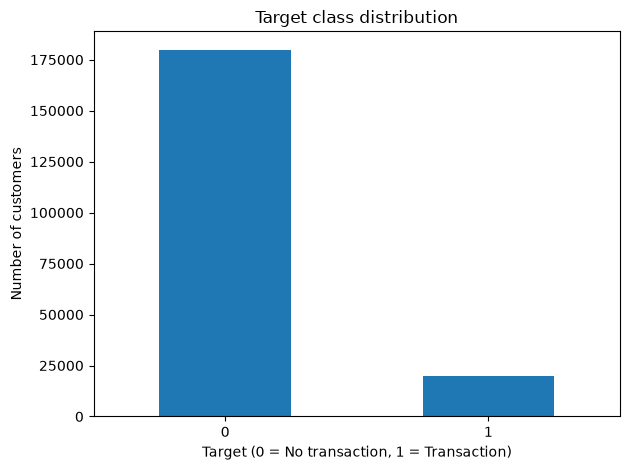

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn data types:")
display(df.dtypes.value_counts().rename_axis("Data type").to_frame("Column count"))

print("\nMissing values (top 15):")
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("Missing count"))

print("\nDuplicate rows:", df.duplicated().sum())

if "target" not in df.columns:
    raise ValueError("The training dataset must contain a 'target' column.")

print("\nTarget values:", sorted(df["target"].dropna().unique().tolist()))
if df["target"].isna().any():
    raise ValueError("Target contains missing values. Resolve them before model training.")
if not set(df["target"].unique()).issubset({0, 1}):
    raise ValueError("Target must contain only binary values 0 and 1.")

class_counts = df["target"].value_counts().sort_index()
class_percent = (df["target"].value_counts(normalize=True).sort_index() * 100).round(2)
class_summary = pd.DataFrame({"Count": class_counts, "Percentage": class_percent})
display(class_summary)

ax = class_counts.plot(kind="bar", rot=0, title="Target class distribution")
ax.set_xlabel("Target (0 = No transaction, 1 = Transaction)")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 5. Prepare features and target

`ID_code` is an identifier, not a customer behaviour measurement, so it is excluded from model features. All remaining columns other than `target` are treated as anonymized predictors. The split is stratified to preserve the target ratio in training and validation data.

In [4]:
# Remove exact duplicate rows, if present.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {before - len(df)}")

drop_columns = ["target"]
if "ID_code" in df.columns:
    drop_columns.append("ID_code")

X = df.drop(columns=drop_columns)
y = df["target"].astype(int)

# Ensure all model inputs are numeric. Non-numeric values are converted to NaN
# and handled by the imputation step in each pipeline.
X = X.apply(pd.to_numeric, errors="coerce")

# Remove columns that contain no usable values or are constant.
all_missing_cols = X.columns[X.isna().all()].tolist()
if all_missing_cols:
    X = X.drop(columns=all_missing_cols)

constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
if constant_cols:
    X = X.drop(columns=constant_cols)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Features excluded as all-missing:", len(all_missing_cols))
print("Constant features removed:", len(constant_cols))

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training set:", X_train.shape)
print("Validation set:", X_valid.shape)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())

Duplicate rows removed: 0
Feature matrix shape: (200000, 200)
Target shape: (200000,)
Features excluded as all-missing: 0
Constant features removed: 0
Training set: (160000, 200)
Validation set: (40000, 200)
Training target distribution:


,Proportion
target,
0,0.899513
1,0.100487


## 6. Model development

The following models provide a useful comparison across different modelling approaches:

- **Dummy Classifier:** baseline reference; predicts the majority class.
- **Logistic Regression:** interpretable linear baseline; scaling is applied.
- **Random Forest:** bagged decision trees that can capture nonlinear relationships.
- **Extra Trees:** randomized tree ensemble; often useful on wide tabular data.
- **HistGradientBoosting:** gradient-boosted decision trees for tabular classification.

Missing numeric values are imputed inside each pipeline. Scaling is used for Logistic Regression and is not required for the tree-based models. `class_weight='balanced'` is used where supported to account for class imbalance.

In [5]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1500, class_weight="balanced",
            solver="liblinear", random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250, max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=250, max_features="sqrt",
            class_weight="balanced",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.08,
            max_leaf_nodes=31, random_state=RANDOM_STATE
        ))
    ])
}
print("Models configured:", list(models.keys()))

Models configured: ['Dummy (most frequent)', 'Logistic Regression', 'Random Forest', 'Extra Trees', 'HistGradientBoosting']


## 7. Train and compare models

The validation threshold is initially set to 0.50 for class predictions. ROC-AUC and Average Precision (PR-AUC) are calculated from predicted probabilities when available. These metrics evaluate ranking quality and are more informative than accuracy alone for an imbalanced target.

In [6]:
results = []
fitted_models = {}
validation_probabilities = {}

for name, model in models.items():
    print(f"Training: {name}")
    model.fit(X_train, y_train)
    fitted_models[name] = model

    pred = model.predict(X_valid)
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_valid)[:, 1]
    elif hasattr(model, "decision_function"):
        raw = model.decision_function(X_valid)
        prob = (raw - raw.min()) / (raw.max() - raw.min() + 1e-12)
    else:
        prob = pred.astype(float)

    validation_probabilities[name] = prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_valid, prob),
        "PR_AUC": average_precision_score(y_valid, prob)
    })

results_df = pd.DataFrame(results).sort_values(
    by=["ROC_AUC", "PR_AUC"], ascending=False
).reset_index(drop=True)

print("Model comparison report:")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1": "{:.4f}", "ROC_AUC": "{:.4f}", "PR_AUC": "{:.4f}"
}))

Training: Dummy (most frequent)
Training: Logistic Regression
Training: Random Forest
Training: Extra Trees
Training: HistGradientBoosting
Model comparison report:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,HistGradientBoosting,0.9093,0.8665,0.1147,0.2025,0.8713,0.5290
1,Logistic Regression,0.7833,0.2865,0.7754,0.4184,0.8599,0.5004
2,Extra Trees,0.8995,0.0000,0.0000,0.0000,0.8180,0.3880
3,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8139,0.3494
4,Dummy (most frequent),0.8995,0.0000,0.0000,0.0000,0.5000,0.1005


## 8. Visual model comparison

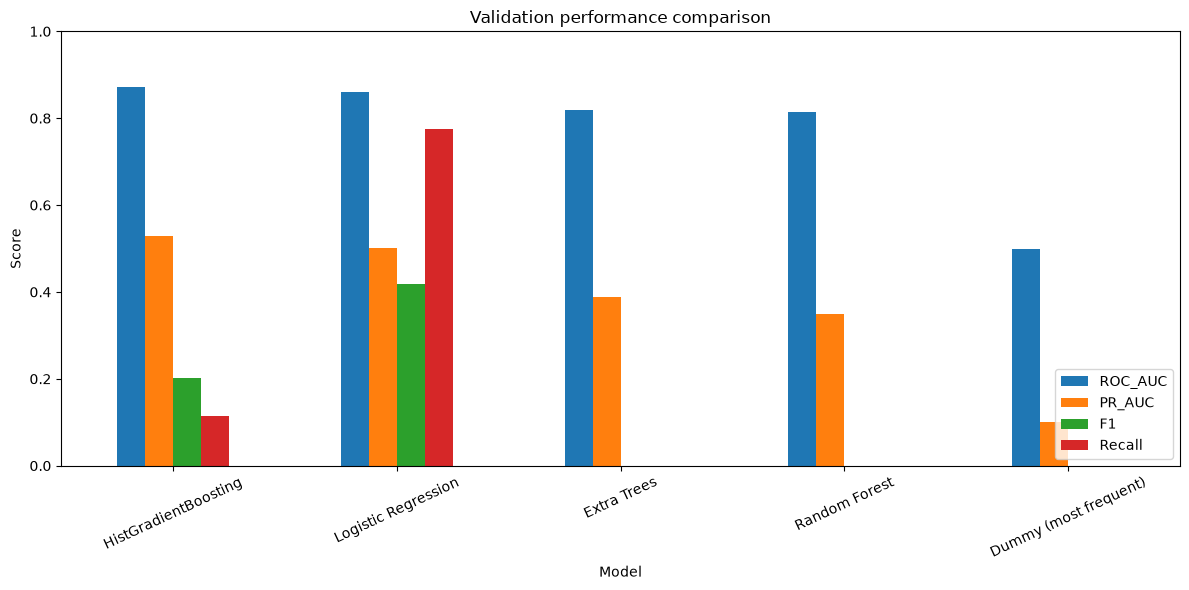

In [7]:
metrics_to_plot = ["ROC_AUC", "PR_AUC", "F1", "Recall"]
plot_df = results_df.set_index("Model")[metrics_to_plot]
ax = plot_df.plot(kind="bar", figsize=(12, 6), ylim=(0, 1), rot=25)
ax.set_title("Validation performance comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. ROC and Precision–Recall curves

The ROC curve shows the trade-off between true-positive and false-positive rates. The Precision–Recall curve focuses on the positive transaction class and is especially useful when positive cases are relatively uncommon.

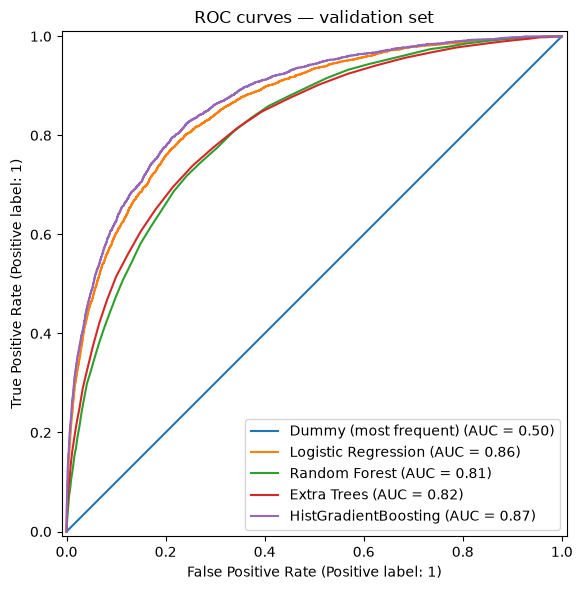

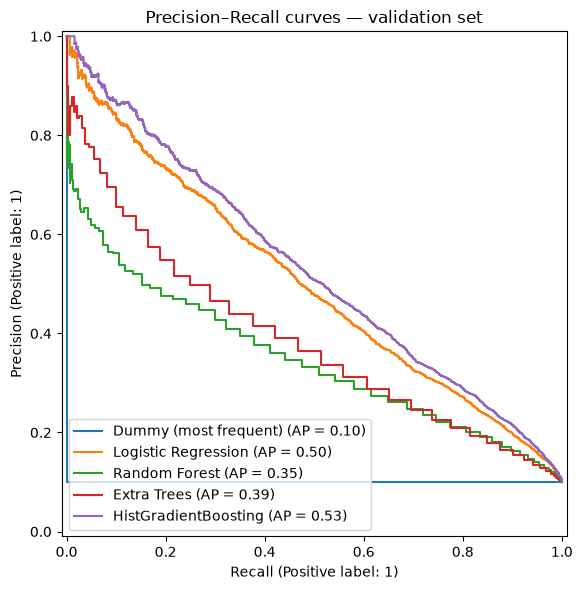

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, prob in validation_probabilities.items():
    RocCurveDisplay.from_predictions(y_valid, prob, name=name, ax=ax)
ax.set_title("ROC curves — validation set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, prob in validation_probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_valid, prob, name=name, ax=ax)
ax.set_title("Precision–Recall curves — validation set")
plt.tight_layout()
plt.show()

## 10. Select the best model and inspect its classification report

The default selection rule ranks models by ROC-AUC, with PR-AUC as a tie-breaker. For a bank, the final choice should also consider the operational cost of false positives and false negatives. If missing a likely transacting customer is costly, recall may receive greater weight; if unnecessary outreach is costly, precision may receive greater weight.

Selected model: HistGradientBoosting

Classification report at threshold 0.50:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     35980
           1       0.87      0.11      0.20      4020

    accuracy                           0.91     40000
   macro avg       0.89      0.56      0.58     40000
weighted avg       0.91      0.91      0.88     40000



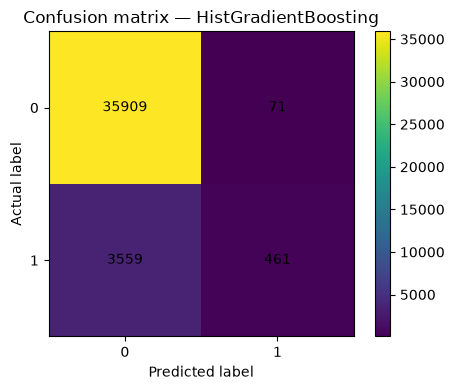

In [9]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_prob = validation_probabilities[best_model_name]
best_pred = (best_prob >= 0.50).astype(int)

print("Selected model:", best_model_name)
print("\nClassification report at threshold 0.50:")
print(classification_report(y_valid, best_pred, zero_division=0))

cm = confusion_matrix(y_valid, best_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title(f"Confusion matrix — {best_model_name}")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], ["0", "1"])
ax.set_yticks([0, 1], ["0", "1"])
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 11. Threshold analysis

A 0.50 probability threshold is not necessarily optimal for a banking use case. The table below shows precision, recall, and F1 at several thresholds. Choose a threshold based on business costs and validation results, not accuracy alone.

In [10]:
threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred_at_threshold = (best_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_valid, pred_at_threshold, zero_division=0),
        "Recall": recall_score(y_valid, pred_at_threshold, zero_division=0),
        "F1": f1_score(y_valid, pred_at_threshold, zero_division=0),
        "Predicted transaction customers": int(pred_at_threshold.sum())
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.style.format({
    "Threshold": "{:.2f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}"
}))

,Threshold,Precision,Recall,F1,Predicted transaction customers
0,0.20,0.4752,0.5450,0.5077,4611
1,0.30,0.6487,0.3450,0.4505,2138
2,0.40,0.7709,0.2085,0.3282,1087
3,0.50,0.8665,0.1147,0.2025,532
4,0.60,0.9218,0.0557,0.1051,243
5,0.70,0.9759,0.0201,0.0395,83


## 12. Production recommendation

The notebook recommends the model with the highest validation ROC-AUC (PR-AUC breaks ties). Review the comparison table and threshold analysis before deployment.

A production deployment should additionally include:
- a separate untouched test set or cross-validation;
- probability calibration and a business-approved decision threshold;
- monitoring for data drift, prediction drift, and changing transaction rates;
- periodic retraining and model versioning;
- checks for fairness, privacy, security, and applicable banking regulations;
- operational validation of inference latency and resource requirements.

The validation winner is a candidate for production testing, not an automatic approval for live banking deployment.

In [11]:
best_row = results_df.iloc[0]
print("FINAL MODEL COMPARISON SUMMARY")
print("--------------------------------")
print("Recommended candidate:", best_row["Model"])
print(f"Validation ROC-AUC: {best_row['ROC_AUC']:.4f}")
print(f"Validation PR-AUC : {best_row['PR_AUC']:.4f}")
print(f"Validation F1     : {best_row['F1']:.4f}")
print(f"Validation Recall : {best_row['Recall']:.4f}")
print("\nRecommendation:")
print(
    f"{best_row['Model']} is the top-ranked candidate under the ROC-AUC "
    "selection rule. Confirm the precision/recall trade-off and business "
    "threshold before production deployment."
)

FINAL MODEL COMPARISON SUMMARY
--------------------------------
Recommended candidate: HistGradientBoosting
Validation ROC-AUC: 0.8713
Validation PR-AUC : 0.5290
Validation F1     : 0.2025
Validation Recall : 0.1147

Recommendation:
HistGradientBoosting is the top-ranked candidate under the ROC-AUC selection rule. Confirm the precision/recall trade-off and business threshold before production deployment.


## 13. Challenges faced and techniques used

| Challenge | Technique used | Reason |
|---|---|---|
| Anonymized feature names | Treat columns as numeric predictors; avoid unsupported business interpretations | The brief states that feature meanings are not provided |
| High-dimensional data (200 features) | Tree ensembles and regularized Logistic Regression | Compare linear and nonlinear approaches |
| Possible class imbalance | Stratified split; class weighting where supported; PR-AUC, recall, precision and F1 | Preserve class ratios and evaluate the positive class |
| Missing values | Median imputation inside pipelines | Avoid losing rows and prevent preprocessing leakage |
| Identifier column (`ID_code`) | Exclude from predictors | IDs identify records and may not generalize as behavioural signals |
| Different feature scales | StandardScaler for Logistic Regression | Scaling supports stable linear-model optimization |
| Threshold-dependent predictions | Threshold analysis | The best operational threshold depends on the cost of false positives and false negatives |
| Model selection | Compare several algorithms on the same validation split | Select based on measured validation performance rather than assumptions |


## 14. Final conclusion

This project builds a binary classification workflow for predicting whether a customer will make a future transaction. It loads the training data from the specified local folder, checks data quality and target distribution, prepares the feature matrix, trains five baseline/ensemble models, compares validation performance, evaluates the selected model, and prints a production-candidate recommendation.